In [62]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from typing import Union
import math
from matplotlib.ticker import FixedLocator, FuncFormatter, MultipleLocator, ScalarFormatter
import aotools
import random
import free_space_fibre_overlap_sim as sim

# ---------- labels -----------
ZERN_INFO = [
    dict(n=0, m=0,  expr=r"1",                          name="Piston"),
    dict(n=1, m=-1, expr=r"r\sin(\theta)",              name="Tilt Y"),
    dict(n=1, m=1,  expr=r"r\cos(\theta)",              name="Tilt X"),
    dict(n=2, m=-2, expr=r"r^{2}\sin(2\theta)",         name="$45\degree$ Astigmatism"),
    dict(n=2, m=0,  expr=r"2r^{2}-1",                   name="Defocus"),
    dict(n=2, m=2,  expr=r"r^{2}\cos(2\theta)",         name="$0\degree$ Astigmatism"),
    dict(n=3, m=-3, expr=r"r^{3}\sin(3\theta)",         name="Trefoil Y"),
    dict(n=3, m=-1, expr=r"(3r^{3}-2r)\sin(\theta)",    name="Y Coma"),
    dict(n=3, m=1,  expr=r"(3r^{3}-2r)\cos(\theta)",    name="X Coma"),
    dict(n=3, m=3,  expr=r"r^{3}\cos(3\theta)",         name="Trefoil X"),
    dict(n=4, m=-4, expr=r"r^{4}\sin(4\theta)",         name="Tetrafoil Y"),
    dict(n=4, m=-2, expr=r"(4r^{4}-3r^{2})\sin(2\theta)", name="Secondary Astigmatism Y"),
    dict(n=4, m=0,  expr=r"6r^{4}-6r^{2}+1",            name="3rd Order Spherical"),
    dict(n=4, m=2,  expr=r"(4r^{4}-3r^{2})\cos(2\theta)", name="Secondary Astigmatism X"),
    dict(n=4, m=4,  expr=r"r^{4}\cos(4\theta)",         name="Tetrafoil X"),
]

def gaussian_input_on_pupil(R: np.ndarray, mask: np.ndarray, u_in: float) -> np.ndarray:
    """
    Input *field* amplitude on the pupil: G(r) = exp[-(r/u_in)^2].
    u_in is the 1/e field radius in the same normalized units as R (pupil radius = 1).
    """
    G = np.zeros_like(R, dtype=np.float64)
    G[mask] = np.exp(-(R[mask]**2) / (u_in**2))
    return G

def zern_label(j: int, style: str = "short") -> str:
    z = ZERN_INFO[j-1]
    if style == "short":
        return f"{z['name']}"
    return rf"$Z_{{{z['n']}}}^{{{z['m']}}}(r,\theta)={z['expr']}$ — {z['name']}"

# --- helpers ---
def _to_knn(arr: np.ndarray) -> np.ndarray:
    if arr.ndim == 2: return arr[None, ...].astype(np.float64)
    if arr.ndim != 3: raise ValueError(f"Unsupported rank {arr.ndim}")
    s0,s1,s2 = arr.shape
    if s1==s2 and s0!=s1: out = arr
    elif s0==s1 and s0!=s2: out = np.moveaxis(arr,-1,0)
    elif s0==s2 and s0!=s1: out = np.moveaxis(arr,1,0)
    else:
        k_axis = int(np.argmin([s0,s1,s2]))
        out = arr if k_axis==0 else np.moveaxis(arr,k_axis,0)
        K,N1,N2 = out.shape
        if N1!=N2: raise ValueError(f"Cannot coerce {arr.shape} to (K,N,N)")
    return out.astype(np.float64)

def load_zernike_stack(path: Union[str, Path]) -> np.ndarray:
    return _to_knn(np.load(path))

def unit_disk_grid(n: int):
    xs = (np.arange(n) - (n - 1)/2.0) * (2.0/n)
    ys = (np.arange(n) - (n - 1)/2.0) * (2.0/n)
    X, Y = np.meshgrid(xs, ys, indexing="xy")
    R = np.sqrt(X**2 + Y**2)
    mask = R <= 1.0 + 1e-12
    dA = (2.0/n)**2
    return R, mask, dA

def gaussian_on_pupil(R, mask, u0: float):
    M = np.zeros_like(R, dtype=np.float64)
    M[mask] = np.exp(-(R[mask]**2) / (u0**2))
    return M

# ---------- core overlap (now returns complex A as well) ----------
def phase_and_intensity_vs_coeff(
    mode2d: np.ndarray,
    R: np.ndarray,
    mask: np.ndarray,
    dA: float,
    u0: float,
    c_vals: np.ndarray,
    u_in: float = None,         # NEW: input-beam 1/e radius (field)
    G_in: np.ndarray = None     # NEW: optional full 2D input field, overrides u_in
):
    """
    Exact normalized overlap on a sampled pupil, now allowing an input beam G.
      Fiber field  : M(r) = exp[-(r/u0)^2]
      Input field  : G(r) = exp[-(r/u_in)^2]  (if u_in is given)
                     or a provided 2D field G_in
                     or uniform top-hat if neither is given.

    Returns: (th, I, A_out) where th = arg(A), I = |A|^2, A_out = complex A.
    """
    # Fiber field (LP01 envelope in pupil plane)
    M = gaussian_on_pupil(R, mask, u0)

    # Input field (illumination)
    if G_in is not None:
        # use provided field inside the pupil (coerce zeros outside)
        G = np.zeros_like(R, dtype=np.complex128)
        G[mask] = np.asarray(G_in, dtype=np.complex128)[mask]
    elif u_in is not None:
        G = gaussian_input_on_pupil(R, mask, u_in).astype(np.complex128)
    else:
        # uniform illumination (your previous behavior)
        G = np.zeros_like(R, dtype=np.complex128)
        G[mask] = 1.0

    # vectors on the pupil
    m   = mode2d[mask].astype(np.float64)                   # Zernike values
    gin = G[mask]                                           # input field
    w   = M[mask].astype(np.float64)                        # fiber field

    # Proper normalization with the actual fields
    norm_E = math.sqrt(np.sum(np.abs(gin)**2) * dA)         # ||G||
    norm_M = math.sqrt(np.sum(w**2) * dA)                   # ||M||

    th = np.empty_like(c_vals, dtype=np.float64)
    I  = np.empty_like(c_vals, dtype=np.float64)
    A_out = np.empty_like(c_vals, dtype=np.complex128)

    if norm_E == 0.0 or norm_M == 0.0:
        th[:] = 0.0; I[:] = 0.0; A_out[:] = 0j
        return th, I, A_out

    scale = dA / (norm_E * norm_M)

    # start at c0
    c0 = float(c_vals[0])
    E = np.exp(1j * (c0 * m)) if c0 != 0.0 else np.ones_like(m, dtype=np.complex128)
    A = scale * np.sum(E * gin * w)
    A_out[0] = A
    th[0] = np.angle(A); I[0] = float(np.abs(A)**2)

    # incremental update for uniform c-grid
    if len(c_vals) > 1:
        dc = float(c_vals[1] - c_vals[0])
        q  = np.exp(1j * (dc * m))
        for k in range(1, len(c_vals)):
            E *= q
            A = scale * np.sum(E * gin * w)
            A_out[k] = A
            th[k] = np.angle(A); I[k] = float(np.abs(A)**2)

    return th, I, A_out

# ---------- π tick helpers ----------
_PI_MAJOR = np.array([-np.pi, -np.pi/2, 0.0, np.pi/2, np.pi])

def _pi_formatter():
    lab = {
        -np.pi:  r"$-\pi$",
        -np.pi/2: r"$-\frac{\pi}{2}$",
        0.0:     r"$0$",
        np.pi/2: r"$\frac{\pi}{2}$",
        np.pi:   r"$\pi$",
    }
    return FuncFormatter(lambda val, pos: lab.get(
        _PI_MAJOR[np.argmin(np.abs(_PI_MAJOR - val))] if np.min(np.abs(_PI_MAJOR - val)) < 1e-6 else val,
        rf"${val/np.pi:.2g}\pi$"
    ))

def apply_pi_ticks(ax):
    ax.set_ylim(-np.pi, np.pi)
    ax.yaxis.set_major_locator(FixedLocator(_PI_MAJOR))
    ax.yaxis.set_major_formatter(_pi_formatter())

def _fmt_pi_major(x, pos):
    k = int(np.round(x/np.pi))
    if abs(x/np.pi - k) > 1e-6: return ""
    if k == 0: return r"$0$"
    s = "-" if k < 0 else ""
    kabs = abs(k)
    return rf"${s}\pi$" if kabs == 1 else rf"${s}{kabs}\pi$"

def apply_pi_xticks(ax, max_mult=4, show_minors=True):
    ax.set_xlim(-max_mult*np.pi, max_mult*np.pi)
    ax.xaxis.set_major_locator(MultipleLocator(base=np.pi))
    ax.xaxis.set_major_formatter(FuncFormatter(_fmt_pi_major))
    if show_minors:
        ax.xaxis.set_minor_locator(MultipleLocator(base=np.pi/2))
def weighted_mean_m(mode2d, u0):
    """⟨m⟩_w with Gaussian weight; not used for the rule, but handy if you prefer a numeric criterion."""
    N = mode2d.shape[0]
    R, mask, dA = unit_disk_grid(N)
    M = gaussian_on_pupil(R, mask, u0)
    m = mode2d[mask]; w = M[mask]
    return float(np.sum(m*w)*dA / (np.sum(w)*dA))

# ---- extra helper for λ (waves) ticks on the x-axis ----
def apply_wave_xticks(ax, coeff_max_rad, show_minors=True):
    """
    Label x in 'waves' (multiples of λ) while data remain in radians.
    Major ticks at integer waves within [-coeff_max, +coeff_max].
    """
    ax.set_xlim(-coeff_max_rad, coeff_max_rad)

    def fmt_waves(x_rad, pos):
        w = x_rad / (2*np.pi)
        k = int(np.round(w))
        if abs(w - k) > 1e-6:
            return ""                        # only label integers
        if k == 0: return r"$0$"
        s = "-" if k < 0 else ""
        kabs = abs(k)
        return rf"${s}\lambda$" if kabs == 1 else rf"${s}{kabs}\,\lambda$"

    ax.xaxis.set_major_locator(MultipleLocator(base=2*np.pi))  # 1 wave
    ax.xaxis.set_major_formatter(FuncFormatter(fmt_waves))
    if show_minors:
        ax.xaxis.set_minor_locator(MultipleLocator(base=np.pi))  # 1/2 wave


# ---- robust 0/π phase for (nearly) real overlaps ----
def phase_binary_from_real(A, I, Imin, eta=1e-3):
    """
    Produce a 0/π phase where overlap is effectively real (|Im(A)| ≤ eta*|A|),
    fall back to raw angle elsewhere; NaN where I ≤ Imin.
    """
    ph = np.full_like(I, np.nan, dtype=float)
    valid = I > Imin
    Aval = A[valid]
    mag  = np.abs(Aval)
    realish = np.abs(Aval.imag) <= eta * np.maximum(mag, 1e-15)
    out = np.empty_like(Aval.real)
    out[realish]  = np.where(Aval.real[realish] >= 0.0, 0.0, np.pi-0.1)
    out[~realish] = np.angle(Aval[~realish])
    ph[valid] = out
    return ph
    
def phase_to_opd(phi_rad: np.ndarray, wavelength_m: float) -> np.ndarray:
    """Wavefront OPD (meters) from phase (radians)."""
    return (wavelength_m / (2.0 * np.pi)) * phi_rad

def zernikes_to_opd(Z_stack: np.ndarray, coeff_rad: np.ndarray, wavelength_m: float) -> np.ndarray:
    """
    Z_stack: shape (K, N, N) Zernike modes (dimensionless).
    coeff_rad: shape (K,) coefficients in radians of phase.
    Returns OPD map (meters).
    """
    phi = np.tensordot(coeff_rad, Z_stack, axes=(0, 0))  # (N, N) phase in rad
    return phase_to_opd(phi, wavelength_m)
def phase_to_mirror_height(phi_rad: np.ndarray, wavelength_m: float) -> np.ndarray:
    """Surface height for a reflective mirror producing phase phi."""
    return (wavelength_m / (4.0 * np.pi)) * phi_rad
def phase_to_thickness(phi_rad: np.ndarray, wavelength_m: float, n: float, n0: float = 1.0) -> np.ndarray:
    """
    Material thickness t (meters) that produces phase phi for transmission through (n) in ambient n0.
    """
    dn = (n - n0)
    if abs(dn) < 1e-12:
        raise ValueError("n - n0 too small to compute transmissive thickness.")
    return (wavelength_m / (2.0 * np.pi * dn)) * phi_rad
    
# --- helper: draw vertical guides at multiples of λ (i.e., a = 2π n) ---
def draw_lambda_guides(ax, coeff_max,
                       include_zero=True, color="0.6", lw=1.0, ls=":", alpha=0.6):
    """
    Draw dotted vertical lines at a = 2π n (n ∈ ℤ) within [-coeff_max, +coeff_max].
    coeff_max is in radians of phase (your x-data domain).
    """
    step = 2*np.pi  # one wave of phase
    n_min = int(np.ceil(-coeff_max / step))
    n_max = int(np.floor( coeff_max / step))
    for n in range(n_min, n_max + 1):
        if n == 0 and not include_zero:
            continue
        x = n * step
        ax.axvline(x, color=color, lw=lw, ls=ls, alpha=alpha, zorder=0)  # zorder=0 keeps under the data
        
# ===================== PLOTTING FUNCTION =====================
def plot_phase_and_intensity_neat(
    zernike_path="fixedzernike_stack.npy",
    Ksel=15,
    u0=0.30,
    coeff_max=10*np.pi,
    num=401,
    downsample=1,
    Imin=1e-14,
    titles=None,
    figsize=(12, 9),
    header_heights=(0.12,),
    phase_mode="auto",
    x_units="pi",
    row_gap=0.55,
    title_pad=2,
    tick_sizes=9,
    u_in=None
):
    """
    phase_mode:
      'auto'        → m=0 (Z1,Z5,Z13): raw phase; m≠0: robust 0/π where overlap is real-ish
      'raw'         → np.angle(A) (masked by Imin)
      'unwrap'      → unwrap where I>Imin
      'real_binary' → force 0/π everywhere based on sign(Re A)
    x_units:
      'pi'          → ticks at integer multiples of π
      'waves'       → ticks at integer multiples of λ (a/(2π))
    """
    # ---- data prep ----
    Z = load_zernike_stack(zernike_path)
    K, N, _ = Z.shape
    Ksel = min(Ksel, K)
    Z = Z[:Ksel, ::downsample, ::downsample]
    _, Nds, _ = Z.shape
    R, mask, dA = unit_disk_grid(Nds)

    # coefficient sweep (radians)
    c_vals = np.linspace(-coeff_max, coeff_max, num, dtype=np.float64)

    # ---- figure + layout ----
    from matplotlib.gridspec import GridSpec
    plt.rcParams.update({'font.size': 10})
    plt.rc('axes', titlesize=14)
    plt.rc('axes', labelsize=10)
    plt.rcParams.update({
    "font.family": "DejaVu Sans",         # same family for all text
    "mathtext.fontset": "dejavusans",     # mathtext uses same family
    "xtick.labelsize": tick_sizes,
    "ytick.labelsize": tick_sizes,
    })
    nrows, ncols = 5, 3
    mid_row = nrows // 2
    mid_col = ncols // 2

    fig = plt.figure(figsize=figsize)
    gs = GridSpec(
        nrows + 1, ncols, figure=fig,
        height_ratios=[header_heights[0]] + [1]*nrows,
        hspace=row_gap, wspace=0.1
    )
    title_ax = fig.add_subplot(gs[0, :]); title_ax.axis("off")

    axes = [fig.add_subplot(gs[r+1, c]) for r in range(nrows) for c in range(ncols)]

    # x ticks/limits once for all panels
    if x_units == "waves":
        for ax in axes: apply_wave_xticks(ax, coeff_max, show_minors=True)
    else:
        max_mult = int(round(coeff_max/np.pi))
        for ax in axes: apply_pi_xticks(ax, max_mult=max_mult, show_minors=True)

    phase_handle = intensity_handle = None

    # ---- plot each mode ----
    for k in range(Ksel):
        ax = axes[k]
        res = phase_and_intensity_vs_coeff(Z[k], R, mask, dA, u0, c_vals, u_in=u_in)
        if len(res) == 3:
            th, I, A = res
        else:
            th, I = res
            A = np.sqrt(np.clip(I, 0.0, None)) * np.exp(1j * th)

        # phase selection
        if phase_mode == "auto":
            m = ZERN_INFO[k]["m"]
            if m == 0:
                ph = np.where(I > Imin, th, np.nan)
            else:
                ph = phase_binary_from_real(A, I, Imin, eta=1e-3)
        elif phase_mode == "unwrap":
            valid = I > Imin
            ph = np.full_like(th, np.nan); ph[valid] = np.unwrap(th[valid], discont=np.pi/2)
        elif phase_mode == "real_binary":
            ph = phase_binary_from_real(A, I, Imin, eta=1e-3)
        else:
            ph = np.where(I > Imin, th, np.nan)

        # left axis: arg(A)
        h1, = ax.plot(c_vals, ph,color="tab:orange", label="arg(C)", lw=1.0)
        apply_pi_ticks(ax)
        ax.grid(True, alpha=0.3)
        ax.tick_params(axis="both", which="both", labelsize=tick_sizes)
        
        # right axis: |A|^2
        ax2 = ax.twinx()
        h2, = ax2.plot(c_vals, I, color="tab:blue", label="|C|²")
        ax2.set_ylim(0, 1)
        fmt_math = ScalarFormatter(useMathText=True)
        fmt_math.set_useOffset(False)
        ax2.yaxis.set_major_formatter(fmt_math)
        ax2.tick_params(axis="both", which="both", labelsize=9)

        row, col = divmod(k, ncols)
        if col != ncols - 1:
            ax2.spines["right"].set_visible(False)
            ax2.tick_params(right=False, labelright=False)

        # Titles (tight to axes) with math subscript for index
        if titles and k < len(titles):
            ax.set_title(titles[k], fontsize=9, pad=title_pad)
        else:
            ax.set_title(rf"$Z_{{{k+1}}}$: {zern_label(k+1, 'short')}", size=11, pad=title_pad)
        if x_units == "waves":
            draw_lambda_guides(ax, coeff_max, include_zero=True, color="black", lw=1.1, ls=":", alpha=1.0)
        # de-duplicate ticks
        if row < nrows - 1: ax.tick_params(labelbottom=False)
        if col > 0:         ax.tick_params(labelleft=False)

        if col == 0 and row == mid_row: ax.set_ylabel("$ϕ$ [rad]", size=16)
        if col == ncols - 1 and row == mid_row: ax2.set_ylabel("$\eta_C$", size=16)
        if row == nrows - 1 and col == mid_col:
            if x_units == "waves":
                ax.set_xlabel("Zernike Coefficient $a_{j}$ [wavelength]", size=14)
            else:
                ax.set_xlabel("Zernike Coefficient $a_{j}$ [rad]", size=14)

        if phase_handle is None:
            phase_handle, intensity_handle = h1, h2

    # blank any unused panels
    for k in range(Ksel, nrows*ncols):
        axes[k].axis("off")

    # ---- title + figure-level legend (tucked under the title) ----
    title_ax.text(0.5, 0.995, "Complex Coupled Amplitude Simulation plots", ha="center", va="top", transform=title_ax.transAxes, size=14)

    fig.legend(
        [intensity_handle, phase_handle], ["|C|²","arg(C)"],
        loc="upper center", bbox_to_anchor=(0.510, 0.975),
        ncol=2, frameon=False, handlelength=2.8, columnspacing=1.2
    )

    # a touch more headroom for the title + legend
    fig.subplots_adjust(left=0.08, right=0.95, bottom=0.08, top=0.985)
    fig.savefig('ZernikePhaseWrapping4test.pdf', dpi=300)
    plt.show()


In [55]:
pixels=1024
zernike_array1 = [aotools.zernike_noll(1, pixels),aotools.zernike_nm(1, -1, pixels),aotools.zernike_nm(1, 1, pixels),aotools.zernike_nm(2, -2, pixels),aotools.zernike_nm(2, 0, pixels),aotools.zernike_nm(2, 2, pixels),aotools.zernike_nm(3,-3, pixels),aotools.zernike_nm(3, -1, pixels),aotools.zernike_nm(3, 1, pixels),aotools.zernike_nm(3, 3, pixels),aotools.zernike_nm(4, -4, pixels),aotools.zernike_nm(4, -2, pixels),aotools.zernike_nm(4, 0, pixels),aotools.zernike_nm(4, 2, pixels),aotools.zernike_nm(4, 4, pixels)]
np.save('zernike_array1', zernike_array1)

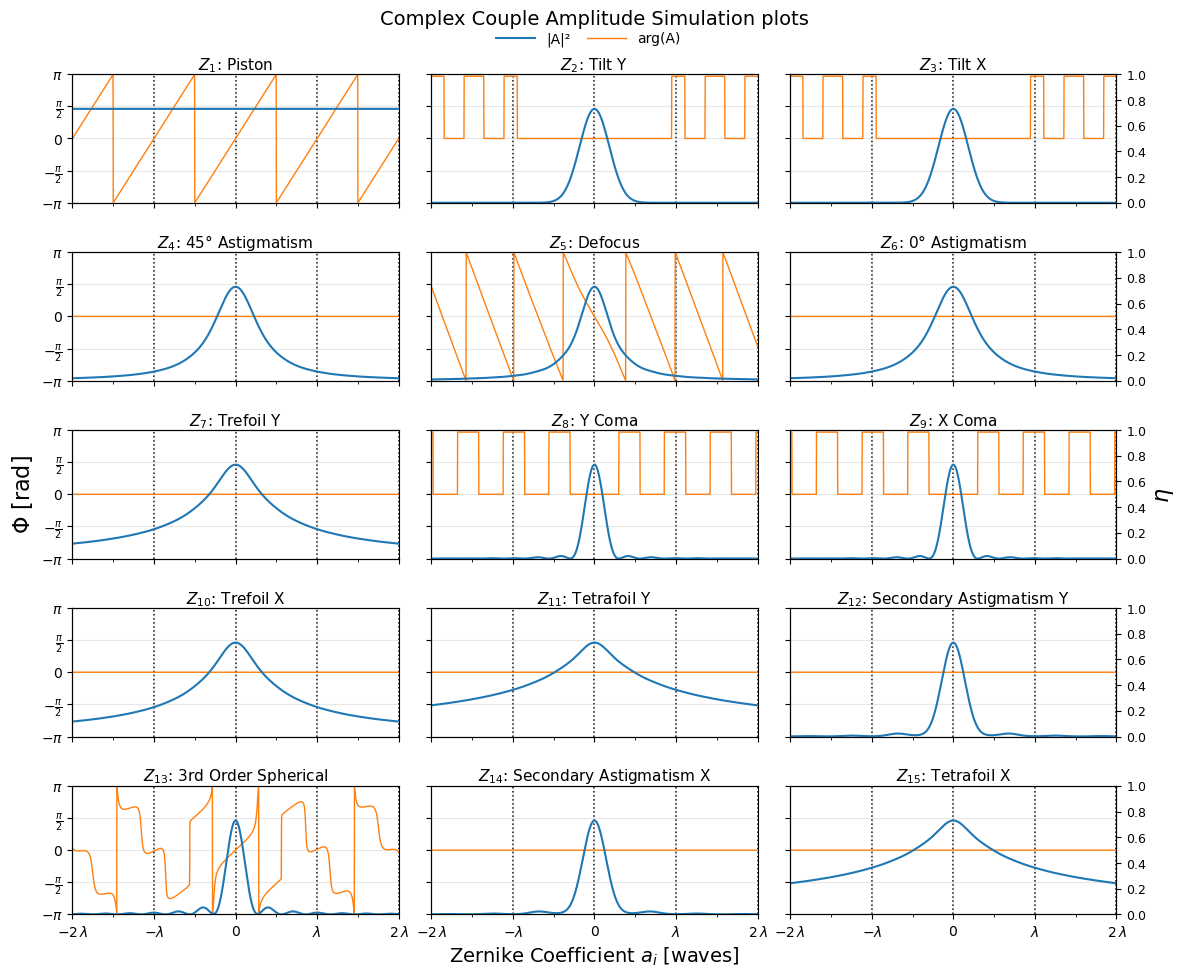

In [13]:
plot_phase_and_intensity_neat(
    zernike_path="zernike_array1.npy",
    Ksel=15,
    u0=1,
    coeff_max=4*np.pi,
    num=1601,
    figsize=(12, 10),
    Imin=4.677290533825251e-29,
    x_units="waves",
    phase_mode="auto",   # try "unwrap" too
    row_gap=0.45,                      # <<< more space between rows
    title_pad=1,
    tick_sizes=10,
    downsample=1,
    u_in=0.5,
)

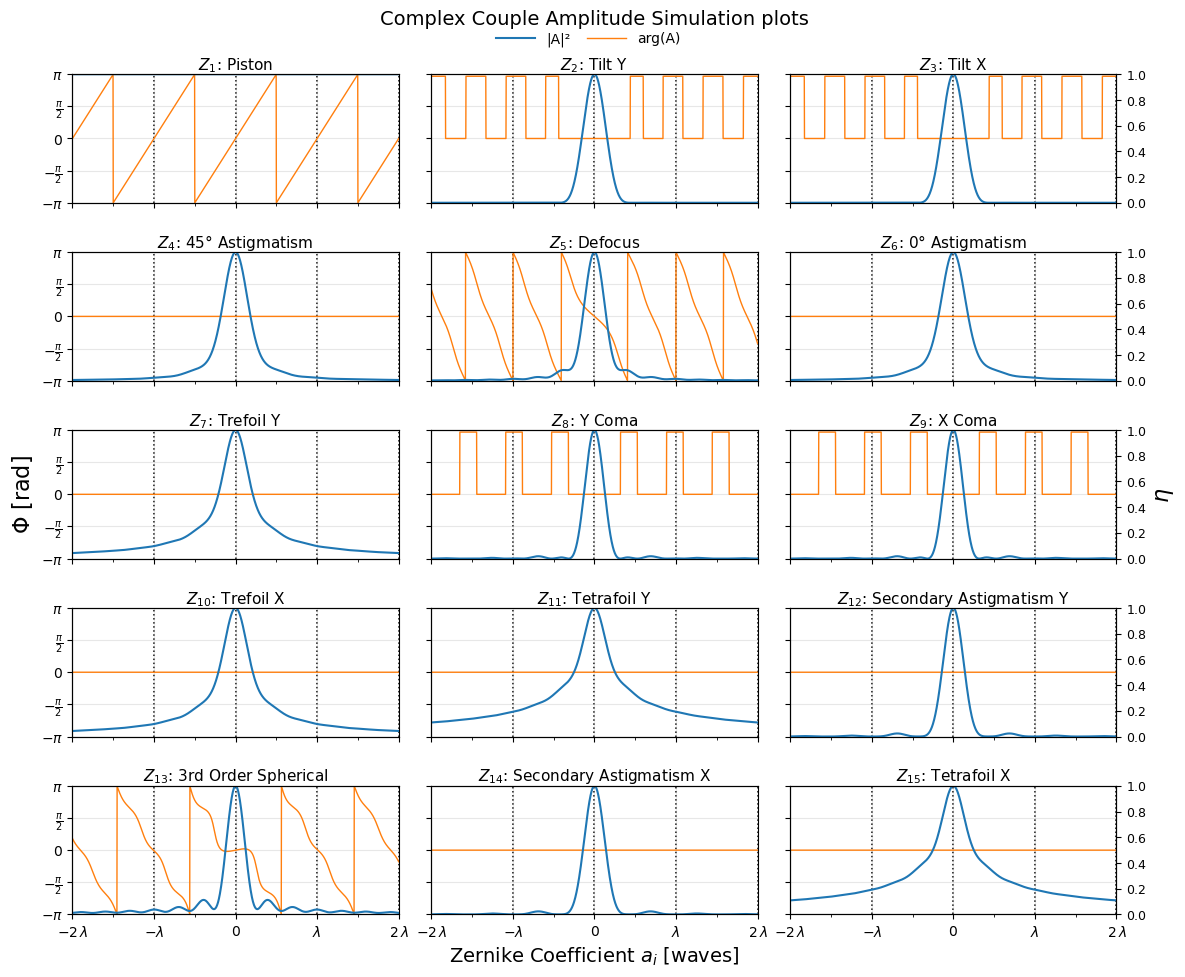

In [14]:
plot_phase_and_intensity_neat(
    zernike_path="zernike_array1.npy",
    Ksel=15,
    u0=1,
    coeff_max=4*np.pi,
    num=1601,
    figsize=(12, 10),
    Imin=4.677290533825251e-29,
    x_units="waves",
    phase_mode="auto",   # try "unwrap" too
    row_gap=0.45,                      # <<< more space between rows
    title_pad=1,
    tick_sizes=10,
    downsample=1,
    u_in=1.0,
)

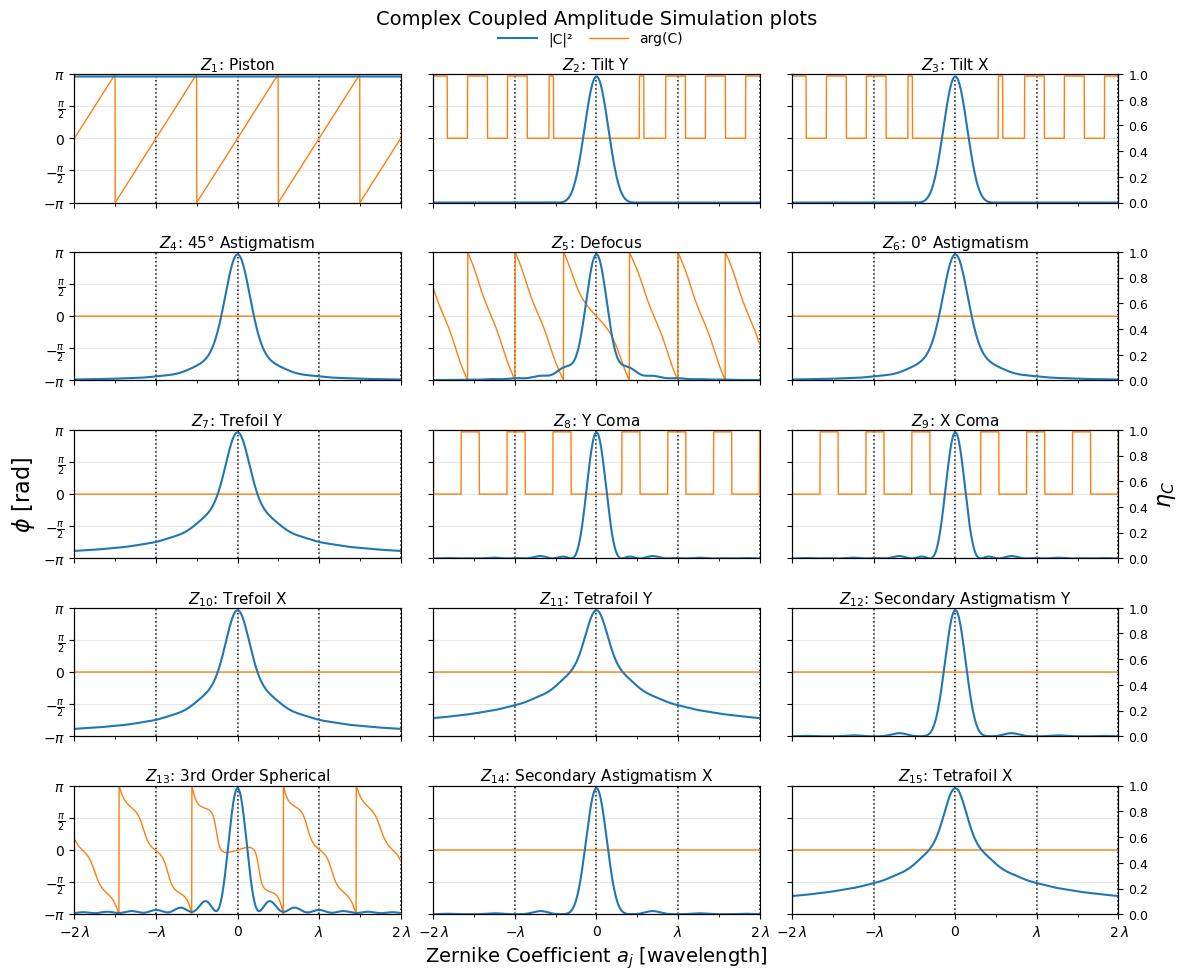

In [64]:
plot_phase_and_intensity_neat(
    zernike_path="zernike_array1.npy",
    Ksel=15,
    u0=1,
    coeff_max=4*np.pi,
    num=1601,
    figsize=(12, 10),
    Imin=4.677290533825251e-29,
    x_units="waves",
    phase_mode="auto",   # try "unwrap" too
    row_gap=0.45,                      # <<< more space between rows
    title_pad=1,
    tick_sizes=10,
    downsample=1,
    u_in=0.8,
)